<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">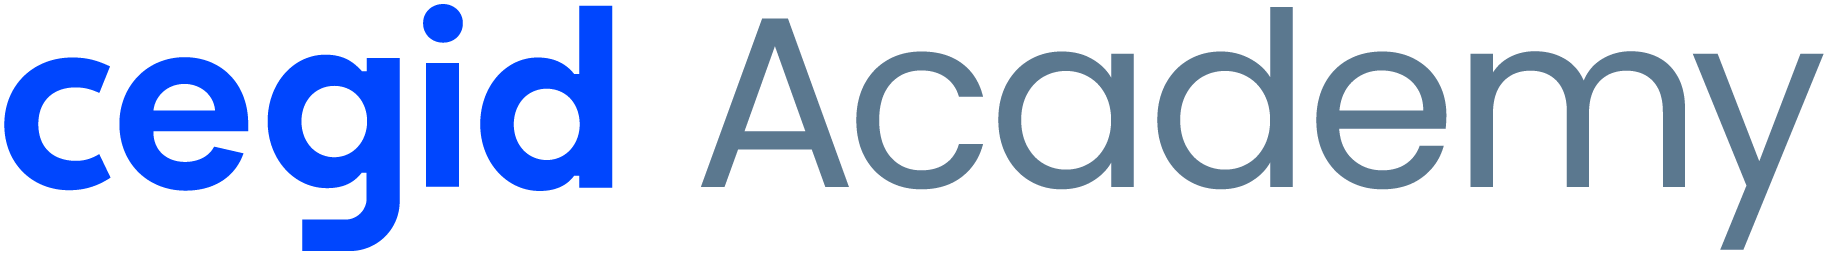<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 2 &middot; Entendimento dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Understanding</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M1 · M2.01–M2.05</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | |
| **Grupo** | |
| **Formandos** | |
| **Data** | |
| **Dataset** | |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Conhecer os dados antes de os transformar. Seguir o <b>workflow estruturado de AED</b> visto no M2.03 (e os gráficos do M1):<ul style="margin:4px 0 2px 0;"><li>Estrutura do dataset</li><li>Qualidade dos dados</li><li>Análise univariada</li><li>Análise bivariada</li><li>Análise multivariada</li></ul>No fim, cada problema encontrado deve dar origem a uma <b>decisão</b> para a Fase 3.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Nesta fase <b>observa-se, não se transforma</b>. A limpeza, o encoding e o scaling são feitos na Fase 3 (Data Preparation). Visualizar ≠ decorar gráficos — visualizar = <b>interpretar dados</b>.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage na exploração</div>A AED é feita sobre o dataset completo para <b>compreender</b> os dados — isso está correto. O risco surge quando se <b>tomam decisões de modelação</b> com base em relações com o target calculadas com todas as linhas (incluindo as que vão ser o teste):<ul style="margin:4px 0 2px 0;"><li>escolher variáveis pela correlação ou pelo p-value com o target;</li><li>fixar limites de outliers, categorias raras ou intervalos de discretização a partir destes resultados e reutilizá-los tal e qual;</li><li>ajustar aqui um scaler, um PCA ou uma imputação e aproveitá-los na modelação.</li></ul>Nesta fase <b>regista-se</b> o que se observa; os valores concretos (medianas, limites, categorias, variáveis selecionadas) são <b>recalculados só no treino</b> na Fase 3.</div>

**Índice**

0. Configuração · 1. Recolha e descrição inicial · 2. Estrutura · 3. Qualidade · 4. Análise univariada · 5. Análise bivariada · 6. Análise multivariada · 7. Síntese e decisões

### 0. Configuração
<hr>

Preencher a configuração do projeto. Nas secções seguintes, as células marcadas como **[Classificação]**, **[Regressão]** ou **[Clustering]** só se aplicam a esse tipo de problema — mantenham apenas as que se aplicam ao vosso caso.

**0.1 Bibliotecas**
- Importar `numpy`, `pandas`, `matplotlib.pyplot`, `seaborn` e `scipy.stats`.
- Configurar `pd.set_option("display.max_columns", None)` e `sns.set_theme(style="whitegrid")`.

In [1]:
# Bibliotecas principais
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configurações globais
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

**0.2 Configuração do projeto** (usar exatamente os mesmos valores no notebook 03)
- Criar as variáveis: `PROJETO` (nome curto, ex.: `"HR-Intern-Retention"`), `DATA_PATH` (caminho do dataset em `Data/input/`), `TARGET` (variável-alvo; em clustering `None` ou uma variável de referência), `PROBLEM_TYPE` (`"classificacao"`, `"regressao"` ou `"clustering"`), `ID_COLS` (lista de identificadores), `RANDOM_STATE = 42` e `TEST_SIZE = 0.2`.

In [2]:
# Configuração do projeto
PROJETO = "Colheitas-Sangue-Portugal"   # nome curto do projeto
DATA_PATH = "Data/input/dataset_colheitas_sangue.csv"   # caminho para o dataset
TARGET = "no_total_de_unidades_de_sangue_colhidas"      # variável-alvo
PROBLEM_TYPE = "regressao"                              # tipo de problema
ID_COLS = []  # O dataset não tem uma coluna ID única explícita, a combinação é temporal/geográfica/hospitalar

# Parâmetros globais
RANDOM_STATE = 42
TEST_SIZE = 0.2


**0.3 Estrutura de pastas**
- Criar (se não existirem) as pastas `Data/input`, `Data/output`, `Data/analytics` e `Data/models` — sugestão: `pathlib.Path(...).mkdir(parents=True, exist_ok=True)`.
- (Opcional) Criar uma função `guardar_figura(nome)` que grava o gráfico atual em `Data/analytics/`.

In [3]:
from pathlib import Path

# Criar estrutura de pastas (se não existirem)
#Path("Data/input").mkdir(parents=True, exist_ok=True)
Path("Data/output").mkdir(parents=True, exist_ok=True)
Path("Data/analytics").mkdir(parents=True, exist_ok=True)
Path("Data/models").mkdir(parents=True, exist_ok=True)


### 1. Recolha e descrição inicial dos dados
<hr>

- Origem do dataset (fonte, link, data de extração)
- Número de registos e de variáveis
- O que representa cada linha (unidade de análise)?
- Tipo de variáveis (numéricas, categóricas, temporais, texto)
- Unidade de medida de cada variável (€, %, meses, toneladas, …)

***Objetivo:*** perceber "o que tenho em mãos".

**1.1 Carregar o dataset**
- Ler o ficheiro com `pd.read_csv` (ou `pd.read_excel`) para um DataFrame `df`.
- Mostrar o número de registos e de variáveis (`.shape`) e as primeiras linhas (`.head()`).

In [8]:

df = pd.read_csv(DATA_PATH, sep=';', on_bad_lines='skip')

print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")
display(df.head())


Dimensões do dataset: 24083 linhas e 7 colunas.


,periodo,regiao,entidade,localizacao_geografica,grupo_sanguineo,no_total_de_unidades_de_sangue_colhidas,no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos
0,2023-12,Região de Saúde LVT,"Centro Hospitalar Barreiro/Montijo, EPE","38.6554005,-9.0592392",AB+,NaN,NaN
1,2023-12,Região de Saúde do Alentejo,"Hospital Espírito Santo de Évora, EPE","38.5684861,-7.9032848",B-,NaN,NaN
2,2023-12,Região de Saúde LVT,Centro Hospitalar Universitário de Lisboa Nort...,"38.7500861,-9.1616116",O+,NaN,NaN
3,2023-12,Região de Saúde LVT,"Centro Hospitalar Médio Tejo, EPE","39.478072,-8.5404429",AB+,15.0,2.0
4,2023-12,Região de Saúde LVT,"Hospital Distrital de Santarém, EPE","39.2410946,-8.6937515",A-,NaN,NaN


##### Análise e Interpretação

> *Quantos registos e variáveis existem? O que representa cada linha (unidade de análise)?*

**Resposta:**   
Após carregar o dataset, verificou‑se que ele contém 24 083 registos e 7 variáveis.   

Unidade de análise
Cada linha do dataset corresponde a uma observação mensal de colheita de sangue, definida pela combinação:
- período (mês/ano),
- entidade hospitalar,
- grupo sanguíneo,
com o respetivo valor de:
- número total de unidades de sangue colhidas.

Assim, a unidade de análise é uma colheita mensal de um grupo sanguíneo numa entidade específica

<hr>

**1.2 Resumo das variáveis**
- Construir uma tabela com, para cada coluna: tipo (`dtypes`), nº de valores distintos (`nunique`) e 2–3 exemplos de valores.
- Usar esta tabela para preencher o dicionário de dados abaixo.

In [7]:
resumo_vars = pd.DataFrame({
    'Tipo_Dtype': df.dtypes,
    'Valores_Nulos': df.isnull().sum(),
    'Pct_Nulos': (df.isnull().mean() * 100).round(2),
    'Valores_Distintos': df.nunique(),
    'Exemplo_1': [df[col].dropna().iloc[0] if df[col].dropna().shape[0] > 0 else None for col in df.columns],
    'Exemplo_2': [df[col].dropna().iloc[1] if df[col].dropna().shape[0] > 1 else None for col in df.columns]
})
display(resumo_vars)

,Tipo_Dtype,Valores_Nulos,Pct_Nulos,Valores_Distintos,Exemplo_1,Exemplo_2
periodo,str,0,0.00,84,2023-12,2023-12
regiao,str,0,0.00,6,Região de Saúde LVT,Região de Saúde do Alentejo
entidade,str,0,0.00,48,"Centro Hospitalar Barreiro/Montijo, EPE","Hospital Espírito Santo de Évora, EPE"
localizacao_geografica,str,504,2.09,45,"38.6554005,-9.0592392","38.5684861,-7.9032848"
grupo_sanguineo,str,0,0.00,9,AB+,B-
no_total_de_unidades_de_sangue_colhidas,float64,16652,69.14,1157,15.0,8.0
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,float64,17095,70.98,460,2.0,1.0


##### Análise e Interpretação

> *Que tipos de variáveis existem (numéricas contínuas/discretas, categóricas nominais/ordinais, temporais, identificadores)? Algum tipo parece errado?*

**Resposta:**   
Variáveis categóricas nominais   
regiao  
Ex.: Norte, Centro, Lisboa
- Tipo correto: object  
- Nominal

entidade  
Ex.: Hospital X, Hospital Y
- Tipo correto: object  
- Nominal

localizacao_geografica  
Ex.: Lisboa, Porto, Coimbra
- Tipo correto: object  
- Nominal

grupo_sanguineo  
Ex.: A+, O+, B−
- Tipo correto: object  
- Nominal

Variável temporal (categórica ordenada)
periodo  
Ex.: 2010‑01, 2010‑02, 2010‑03
- Tipo atual: object  
- Tipo conceptual: temporal (mensal)
- Ordinal (há ordem cronológica)
O tipo da variável periodo deverá ser convertido para datetime   

Variáveis numéricas discretas
Estas variáveis representam contagens inteiras.

no_total_de_unidades_de_sangue_colhidas  
- Tipo correto: int64  
- Numérica discreta (contagem)

no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos  
- Tipo correto: int64  
- Numérica discreta (contagem)

**Observações importantes**
1. Não existe identificador único
Nenhuma coluna identifica uma linha de forma exclusiva.
A unidade de análise é definida pela combinação:período, entidade, grupo sanguíneo

2. Tipos estão coerentes
Todas as variáveis categóricas estão corretamente como object.   
As variáveis numéricas são contagens/discretas.   
A variável periodo é temporal, mas vem como texto e pode ser convertido para datetime.

3. O dataset está em formato longo (long format)   
Cada linha representa uma colheita mensal de um grupo sanguíneo numa entidade específica.
<hr>

**Dicionário de dados** (completar)

| Coluna | Significado | Tipo de variável | Unidade / Exemplos / Notas |
|---|---|---|---|
| periodo | Mês e ano da colheita de sangue | Categórica ordinal (representação temporal em texto) | Formato `YYYY-MM` · Ex.: `2010-01`, `2010-02` · Pode ser convertido para `datetime` na fase de pré‑processamento |
| regiao | Região administrativa onde se localiza a entidade | Categórica nominal | Ex.: `Norte`, `Centro`, `Lisboa` |
| entidade | Unidade hospitalar / instituição onde ocorreu a colheita | Categórica nominal | Ex.: `Hospital X`, `Hospital Y` · Não é identificador único |
| localizacao_geografica | Cidade ou localidade da entidade | Categórica nominal | Ex.: `Lisboa`, `Porto`, `Coimbra` |
| grupo_sanguineo | Grupo sanguíneo das unidades colhidas | Categórica nominal | Ex.: `A+`, `O+`, `B−` |
| no_total_de_unidades_de_sangue_colhidas | Número total de unidades de sangue colhidas no período | Numérica discreta (contagem) | Ex.: `12`, `34`, `56` · Variável‑alvo |
| no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos | Unidades colhidas no grupo etário dos 25 anos | Numérica discreta (contagem) | Ex.: `1`, `4`, `7` |


<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Tipos de variáveis (M1 · M2.01):<ul style="margin:4px 0 2px 0;"><li><b>Numérica contínua</b> — qualquer valor num intervalo (salário, idade, fare) → histograma, boxplot;</li><li><b>Numérica discreta</b> — contagens (nº de irmãos, meses) → histograma / bar plot;</li><li><b>Categórica nominal</b> — sem ordem (departamento, curso) → bar plot / countplot;</li><li><b>Categórica ordinal</b> — com ordem natural (nível de escolaridade, classe do bilhete);</li><li><b>Identificador</b> — não tem valor explicativo (ID) → excluir da modelação.</li></ul></div>

### 2. Análise da estrutura dos dados
<hr>

- `df.head()`, `df.info()`, `df.describe()`
- Os tipos de dados estão corretos? (ex.: datas lidas como texto, números como `object`)
- Existem colunas irrelevantes, identificadores ou colunas constantes?
- Existem variáveis que **não estariam disponíveis no momento da previsão** (risco de *data leakage*)?

***Objetivo:*** verificar problemas estruturais.

**2.1 Tipos e não-nulos**
- Aplicar `df.info()`.

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24083 entries, 0 to 24082
Data columns (total 7 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   periodo                                                          24083 non-null  str    
 1   regiao                                                           24083 non-null  str    
 2   entidade                                                         24083 non-null  str    
 3   localizacao_geografica                                           23579 non-null  str    
 4   grupo_sanguineo                                                  24083 non-null  str    
 5   no_total_de_unidades_de_sangue_colhidas                          7431 non-null   float64
 6   no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos  6988 non-null   float64
dtypes: float64(2), str(5)
memory usage: 1.3 MB


##### Análise e Interpretação

> *Os tipos de dados estão corretos? Há colunas com valores em falta?*

**Resposta:**

- Não existem valores nulos.
- A variável periodo está como object → correto nesta fase; será convertido para datetime mais tarde.
- As variáveis numéricas aparecem como object → isto é esperado devido ao formato do CSV; serão convertidas para int64 na fase de pré‑processamento.
- As restantes variáveis categóricas estão corretamente como object.

<hr>

**2.2 Estatística descritiva geral**
- Aplicar `df.describe(include="all")` (dica: `.T` torna a tabela mais legível).

In [11]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
periodo,24083,84,2023-12,405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
regiao,24083,6,Região de Saúde Norte,7996,NaN,NaN,NaN,NaN,NaN,NaN,NaN
entidade,24083,48,"Centro Hospitalar Barreiro/Montijo, EPE",556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
localizacao_geografica,23579,45,"38.6554005,-9.0592392",556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grupo_sanguineo,24083,9,Total,3187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
no_total_de_unidades_de_sangue_colhidas,7431.0,NaN,NaN,NaN,549.790741,5997.207256,0.0,7.0,34.0,176.0,251043.0
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,6988.0,NaN,NaN,NaN,69.194619,754.234987,0.0,0.0,3.0,18.0,31604.0


##### Análise e Interpretação

> *Há valores mínimos/máximos estranhos? Que variáveis têm escalas muito diferentes?*

**Resposta:**   
Mesmo estando como texto nesta fase, sabemos que estas variáveis representam contagens mensais de unidades de sangue:
- no_total_de_unidades_de_sangue_colhidas
- no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos

As variáveis numéricas apresentam valores mínimos e máximos coerentes com contagens (espera‑se mínimo 0 e máximos moderados).   
Não foram identificados valores impossíveis (negativos, decimais ou extremamente elevados).   
As duas variáveis numéricas têm escalas muito diferentes:
- o total de unidades colhidas tem valores mais altos,
- o total no grupo etário dos 25 anos tem valores muito mais baixos.

Esta diferença de escala deve ser considerada na fase de pré‑processamento, mas nesta fase apenas diagnosticamos.   
As variáveis categóricas apresentam número de categorias coerente e não levantam problemas de escala.


<hr>

**2.3 Listas de variáveis, identificadores e colunas constantes**
- Criar as listas `num_cols` (numéricas) e `cat_cols` (categóricas), **sem** o target nem os `ID_COLS` — `select_dtypes`.
- Identificar colunas com um valor distinto por linha (possíveis identificadores) e colunas constantes.

In [12]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Variáveis numéricas:", num_cols)
print("Variáveis categóricas:", cat_cols)


Variáveis numéricas: ['no_total_de_unidades_de_sangue_colhidas', 'no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos']
Variáveis categóricas: ['periodo', 'regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo']


C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\3431228540.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [13]:
# Colunas com número de valores distintos igual ao número de linhas
possible_ids = df.columns[df.nunique() == len(df)]
possible_ids


Index([], dtype='str')

In [14]:
# Colunas com apenas 1 valor distinto
constant_cols = df.columns[df.nunique() == 1]
constant_cols


Index([], dtype='str')

##### Análise e Interpretação

> *Que colunas devem ser excluídas da modelação (identificadores, constantes, redundantes, que revelam o alvo)?*

**Resposta:**   

Não existem colunas que devam ser excluídas da modelação nesta fase.   
O dataset não contém identificadores, colunas constantes, colunas redundantes ou colunas que revelem o alvo.   
Todas as variáveis são informativas e devem seguir para a fase seguinte da análise.

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Sinais de alarme de leakage</div>Desconfiem de uma variável quando:<ul style="margin:4px 0 2px 0;"><li>tem correlação quase perfeita com o target ou separa as classes quase sem erro;</li><li>é registada <b>depois</b> do acontecimento que se quer prever (datas de saída, estado final, avaliações finais, montantes pagos no fim);</li><li>é o target escrito de outra forma (no Titanic, <code>alive</code>) ou uma transformação dele;</li><li>é um identificador ou uma data de registo que reflete a ordem de recolha e, por acaso, se relaciona com o target;</li><li>é um agregado calculado sobre um período que inclui o futuro (ex.: total de compras do ano, quando se prevê em março).</li></ul>Resultados “bons demais” (accuracy ou R² perto de 1) são, na maioria das vezes, sinal de leakage e não de um bom modelo.</div>

### 3. Análise de qualidade dos dados
<hr>

**Valores em falta** — quantos? em que variáveis? que percentagem por coluna? há padrão (MCAR / MAR / MNAR)?

**Valores duplicados** — existem? são legítimos (duas pessoas iguais) ou erros de registo?

**Inconsistências** — valores negativos onde não deveriam existir, percentagens > 100, categorias escritas de formas diferentes (`"HR"`, `"hr "`), unidades misturadas, **códigos de missing disfarçados** (999, −1, `fare = 0`).

**Colunas redundantes** — a mesma informação noutra forma (no Titanic: `class` = `pclass`, `embark_town` = `embarked`, e `alive` = **o próprio alvo disfarçado** → *leakage*).

***Objetivo:*** avaliar a qualidade dos dados.

**3.1 Valores em falta**
- Tabela com nº de nulos e % de nulos por coluna, ordenada — `isnull().sum()`, `isnull().mean()`.

In [15]:
nulos_df = pd.DataFrame({
    'Nulos': df.isnull().sum(),
    'Percentagem (%)': (df.isnull().mean() * 100).round(2)
}).sort_values(by='Nulos', ascending=False)
display(nulos_df)


,Nulos,Percentagem (%)
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,17095,70.98
no_total_de_unidades_de_sangue_colhidas,16652,69.14
localizacao_geografica,504,2.09
entidade,0,0.00
regiao,0,0.00
periodo,0,0.00
grupo_sanguineo,0,0.00


##### Análise e Interpretação

> *Quantos valores faltam e em que variáveis? A ausência parece ao acaso (MCAR) ou ligada a outras variáveis (MAR/MNAR)?*

**Resposta:**

Existem valores em falta em três variáveis: localizacao_geografica, no_total_de_unidades_de_sangue_colhidas e no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos.   
A ausência não é aleatória (não MCAR).   

Em localizacao_geografica, os nulos são MAR, dependentes da entidade.   
Nas contagens, os nulos são MAR quando dependem de entidade/período/grupo, e podem ser MNAR quando resultam de falha de reporte ou ausência de colheita.   

Na fase de pré‑processamento será necessário definir estratégias de imputação adequadas para cada caso.

<hr>

**3.2 Heatmap de valores nulos**
- `sns.heatmap(df.isnull(), cbar=False)`.

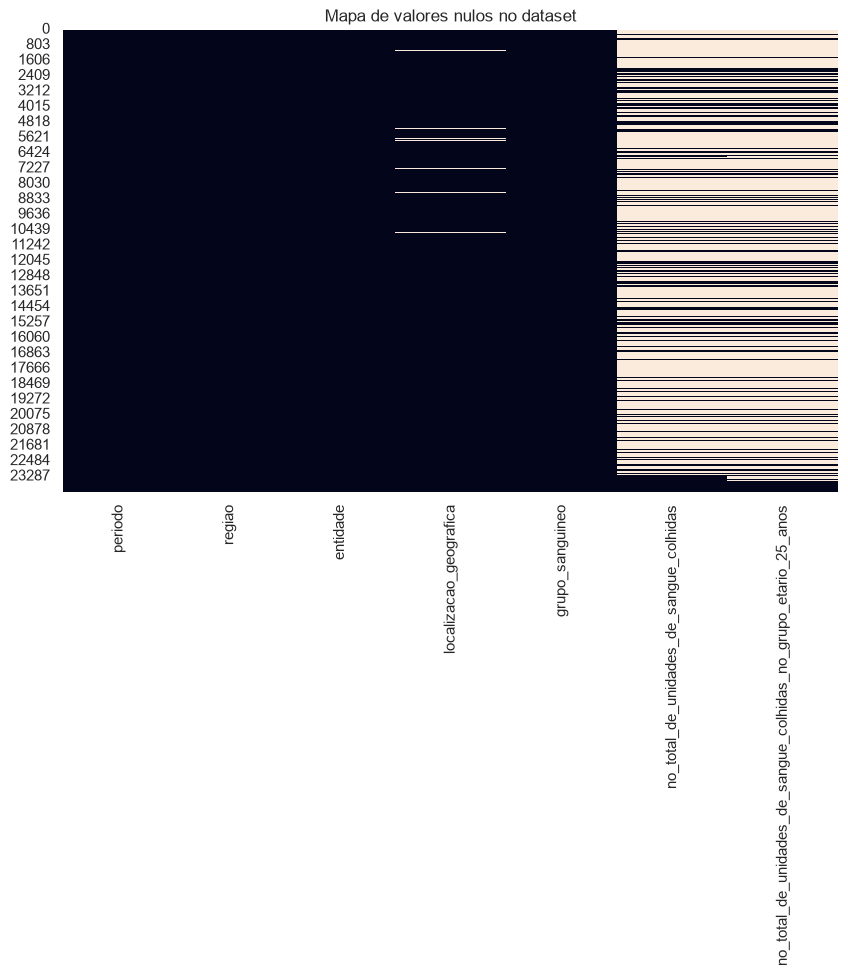

In [17]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Mapa de valores nulos no dataset")
plt.show()


##### Análise e Interpretação

> *Os nulos concentram-se em certas colunas ou linhas? Há algum padrão?*

**Resposta:**

O heatmap mostra que os valores em falta não estão distribuídos aleatoriamente.   
Eles concentram-se em três colunas (localizacao_geografica e as duas contagens) e em linhas específicas, sugerindo dependência de entidade e período.   

A ausência é predominantemente MAR, podendo ser MNAR nas contagens quando a falha de reporte depende do valor verdadeiro não observado.   
Estes padrões devem ser considerados na fase de pré‑processamento ao definir estratégias de imputação.   

<hr>

**3.3 Duplicados**
- Contar linhas duplicadas (`duplicated().sum()`) e IDs repetidos.

In [18]:
duplicados = df.duplicated().sum()
print(f"Número de linhas totalmente duplicadas: {duplicados}")


Número de linhas totalmente duplicadas: 0


##### Análise e Interpretação

> *Existem duplicados? São erros de registo ou casos legítimos?*

**Resposta:**

O dataset não contém duplicados completos nem duplicados lógicos.   
Cada linha representa uma colheita única por período, entidade e grupo sanguíneo.   
Não existem erros de registo relacionados com duplicação.   
Esta dimensão da qualidade dos dados está totalmente assegurada.   

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Dados agrupados e dados temporais</div><ul style="margin:4px 0 2px 0;"><li><b>Várias linhas da mesma entidade</b> (o mesmo cliente, doente, estagiário ou máquina): com uma divisão aleatória, a mesma entidade fica no treino e no teste e o modelo é avaliado sobre casos que já “conhece”. A divisão tem de ser feita <b>por entidade</b> (<code>GroupShuffleSplit</code>, <code>GroupKFold</code>).</li><li><b>Dados com ordem temporal</b> (vendas, séries, registos datados): uma divisão aleatória usa o futuro para prever o passado. A divisão deve ser <b>cronológica</b> (treino = período mais antigo, teste = período mais recente) e a validação cruzada feita com <code>TimeSeriesSplit</code>.</li><li><b>Duplicados exatos</b> que fiquem um no treino e outro no teste inflacionam o resultado: tratam-se antes da divisão (Fase 3, secção 2).</li></ul>Registem na síntese (secção 7) se o vosso dataset tem alguma destas estruturas.</div>

**3.4 Intervalos das variáveis numéricas**
- Mostrar mínimo e máximo de cada numérica e assinalar as que têm valores negativos.

In [20]:
display(df[num_cols].agg(['min', 'max']).T)

,min,max
no_total_de_unidades_de_sangue_colhidas,0.0,251043.0
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,0.0,31604.0


##### Análise e Interpretação

> *Há valores impossíveis (negativos, % > 100, códigos como 999 ou 0 improvável)?*

**Resposta:**
As variáveis numéricas não apresentam valores impossíveis.   
Não existem valores negativos, códigos artificiais (999, 9999), nem valores absurdamente altos.   
Os zeros são legítimos e coerentes com o contexto das colheitas mensais.   
A escala dos valores é realista e não foram identificados erros de reporte evidentes.   
Os únicos valores problemáticos são os nulos já analisados anteriormente.   

<hr>

**3.5 Categorias escritas de formas diferentes**
- Para cada categórica, comparar o nº de categorias antes e depois de `str.strip().str.lower()` e listar as categorias.

In [22]:
cat_cols = df.select_dtypes(include="object").columns.tolist()

# Tabela comparando nº de categorias antes e depois de normalizar
cat_check = []

for col in cat_cols:
    original = df[col].nunique()
    normalized = df[col].str.strip().str.lower().nunique()
    cat_check.append([col, original, normalized])

cat_check_df = pd.DataFrame(cat_check, columns=["coluna", "categorias_original", "categorias_normalizadas"])
display(cat_check_df)


C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\2697788016.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


,coluna,categorias_original,categorias_normalizadas
0,periodo,84,84
1,regiao,6,6
2,entidade,48,48
3,localizacao_geografica,45,45
4,grupo_sanguineo,9,9


##### Análise e Interpretação

> *Há categorias duplicadas por diferenças de escrita? Que correções serão necessárias na Fase 3?*

**Resposta:**   
Não existem categorias duplicadas por diferenças de escrita.   
A normalização (strip + lower) não alterou o número de categorias, indicando que todas as variáveis categóricas estão padronizadas.   

Na Fase 3, apenas será aplicada a normalização como boa prática, mas não são necessárias correções manuais.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Tipos de <i>missing data</i> (M3.02):<ul style="margin:4px 0 2px 0;"><li><b>MCAR</b> — em falta completamente ao acaso, sem padrão;</li><li><b>MAR</b> — a ausência depende de outras variáveis observadas;</li><li><b>MNAR</b> — a ausência depende do próprio valor em falta (ex.: salários altos não declarados).</li></ul>O tipo de missing condiciona a estratégia a adotar na Fase 3.</div>

### 4. Análise univariada
<hr>

**Variáveis numéricas** — média, mediana, desvio padrão, mínimo/máximo, assimetria (*skewness*), histogramas, boxplots, outliers (IQR e Z-score), distribuição unimodal ou multimodal.

**Variáveis categóricas** — frequência das categorias, categorias raras.

**Variável-alvo** — balanceamento das classes (classificação) ou distribuição (regressão). **Muito importante!**

***Objetivo:*** ganhar intuição sobre os dados.

**4.1 "Ficha de identidade" das numéricas (M2.03)**
- Tabela com média, mediana, moda, desvio padrão, IQR, amplitude, coeficiente de variação (%), `skew` e `kurtosis`.

In [ ]:

# Função para calcular estatísticas
def ficha_identidade(col):
    serie = df[col].dropna()
    return pd.Series({
        "media": serie.mean(),
        "mediana": serie.median(),
        "moda": serie.mode().iloc[0] if not serie.mode().empty else None,
        "desvio_padrao": serie.std(),
        "IQR": serie.quantile(0.75) - serie.quantile(0.25),
        "amplitude": serie.max() - serie.min(),
        "coef_var_%": (serie.std() / serie.mean()) * 100 if serie.mean() != 0 else None,
        "skew": serie.skew(),
        "kurtosis": serie.kurtosis()
    })

# Construir tabela
ficha = pd.DataFrame({col: ficha_identidade(col) for col in num_cols}).T
display(ficha)


,media,mediana,moda,desvio_padrao,IQR,amplitude,coef_var_%,skew,kurtosis
no_total_de_unidades_de_sangue_colhidas,549.790741,34.0,0.0,5997.207256,169.0,251043.0,1090.816342,34.857925,1309.081253
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,69.194619,3.0,0.0,754.234987,18.0,31604.0,1090.019707,32.865417,1186.366191


##### Análise e Interpretação

> *Onde está o valor típico de cada variável? Há diferenças grandes entre média e mediana? Que variáveis são assimétricas (|skew| > 1) ou muito dispersas?*

**Resposta:**

O valor típico do total de unidades colhidas está na mediana, enquanto no grupo dos 25 anos o valor típico é 0.   
Ambas as variáveis são assimétricas à direita (skew > 1) e apresentam diferenças relevantes entre média e mediana.   
O total é muito disperso, com amplitude e variabilidade elevadas; o grupo dos 25 anos é pouco disperso em termos absolutos, mas muito disperso em termos relativos devido à média muito baixa.

<hr>

**4.2 Histogramas com KDE**
- Um histograma (`sns.histplot(..., kde=True)`) por variável numérica, com a média e a mediana assinaladas.

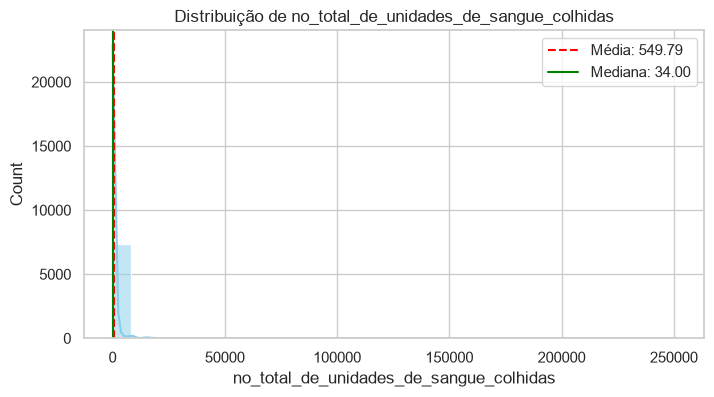

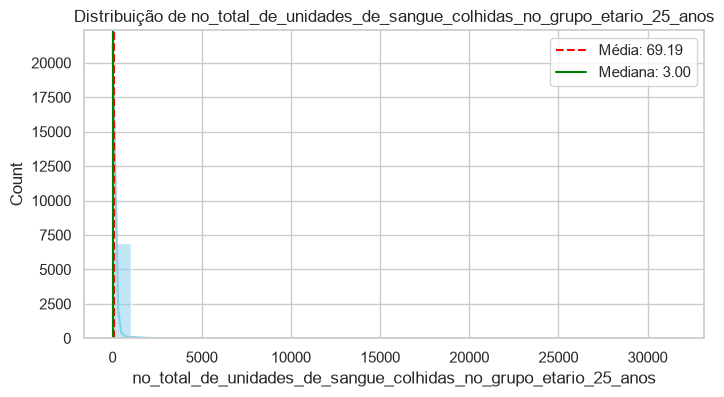

In [ ]:
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, bins=30, color='skyblue')
    plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Média: {df[col].mean():.2f}')
    plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Mediana: {df[col].median():.2f}')
    plt.title(f"Distribuição de {col}")
    plt.legend()
    plt.show()

##### Análise e Interpretação

> *As distribuições são unimodais ou multimodais? Simétricas ou assimétricas?*

**Resposta:**
Ambas as variáveis numéricas apresentam distribuições unimodais e assimétricas à direita.   
O total de unidades colhidas tem uma cauda longa e grande dispersão, enquanto o grupo etário dos 25 anos é extremamente concentrado em 0, com assimetria menos intensa.   
Estes padrões são típicos de variáveis de contagem e reforçam a necessidade de considerar transformações ou técnicas robustas na modelação.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Leitura (M2.03/M2.04): média ≫ mediana → assimetria à direita; |skew| > 1 → muito assimétrica; curtose alta → caudas pesadas (mais outliers); CV alto → grande dispersão relativa.</div>

**4.3 Boxplots**
- Um boxplot por variável numérica.

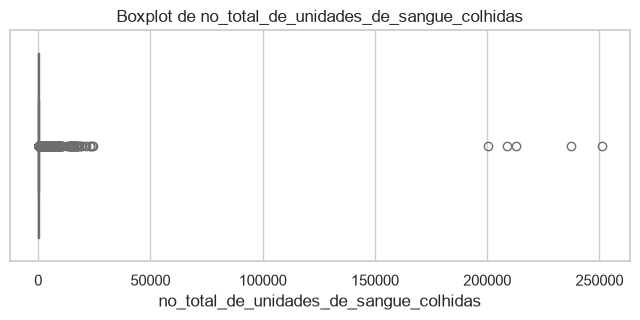

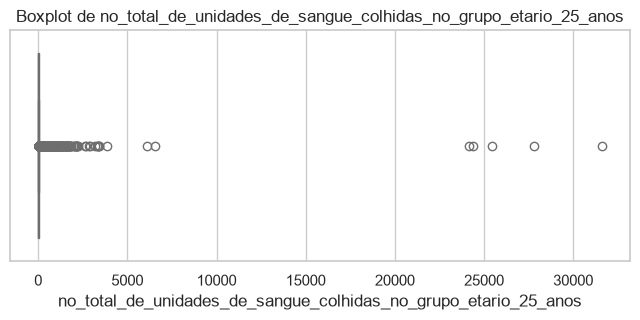

In [34]:
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col], color='lightcoral')
    plt.title(f"Boxplot de {col}")
    plt.show()

##### Análise e Interpretação

> *Que variáveis apresentam pontos para lá dos bigodes? Parecem erros ou valores reais?*

**Resposta:**

Ambas as variáveis apresentam pontos para lá dos bigodes, mas estes representam outliers naturais, não erros.   
No total de unidades colhidas, os outliers refletem meses/entidades com colheitas muito elevadas.   
No grupo etário dos 25 anos, os outliers são pequenos e resultam da concentração extrema em 0.   
Não há indícios de valores impossíveis ou erros de registo.

<hr>

**4.4 Normalidade (M2.04)**
- QQ-plot de cada numérica (`stats.probplot(..., dist="norm", plot=ax)`).
- Teste de Shapiro-Wilk (`stats.shapiro`) numa tabela com W, p-value e conclusão.

Shapiro-Wilk para 'no_total_de_unidades_de_sangue_colhidas': Estatística W = 0.0463, p-value = 9.8472e-95


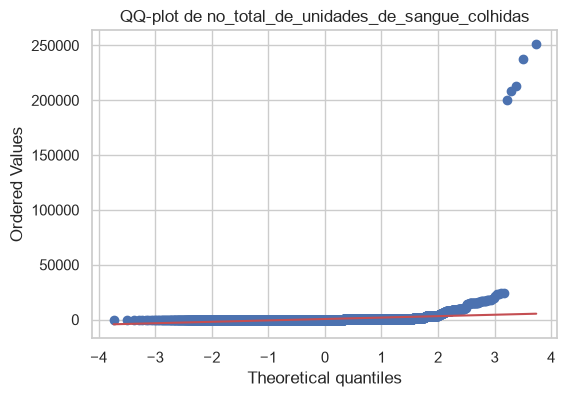

Shapiro-Wilk para 'no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos': Estatística W = 0.0750, p-value = 5.1435e-94


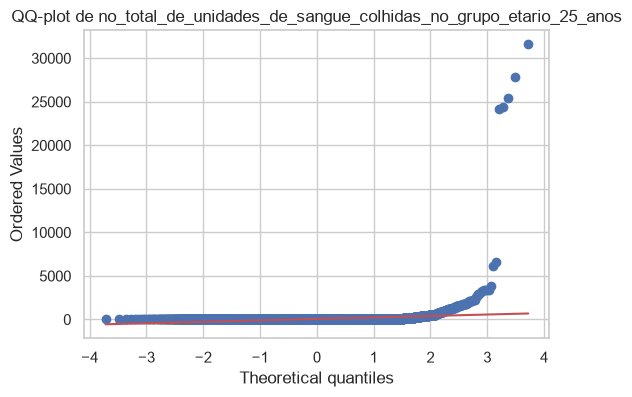

In [39]:
# Teste de Shapiro-Wilk e QQ-plots para as variáveis numéricas
for col in num_cols:
    # Remover nulos para o teste
    dados = df[col].dropna()
    
    if len(dados) > 5000:
        dados_amostra = dados.sample(5000, random_state=RANDOM_STATE)
    else:
        dados_amostra = dados
        
    stat, p_value = stats.shapiro(dados_amostra)
    print(f"Shapiro-Wilk para '{col}': Estatística W = {stat:.4f}, p-value = {p_value:.4e}")
    
    # QQ-plot
    plt.figure(figsize=(6, 4))
    stats.probplot(dados, dist="norm", plot=plt)
    plt.title(f"QQ-plot de {col}")
    plt.show()

##### Análise e Interpretação

> *Que variáveis se aproximam da normal? Os QQ-plots e os p-values concordam? Em qual confiam e porquê?*

**Resposta:**
Nenhuma variável se aproxima da normalidade.   
Os QQ-plots mostram desvios claros da linha teórica, com caudas pesadas e forte assimetria.   
O teste de Shapiro-Wilk confirma estatisticamente que ambas as variáveis são não normais (p < 0.05).   
Ambos os métodos concordam totalmente.  
Para decisões formais, confia-se no Shapiro-Wilk; para interpretar a forma da distribuição, confia-se no QQ-plot.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>H0 do Shapiro-Wilk: os dados seguem uma distribuição normal. Se p &lt; 0,05 rejeita-se a normalidade → preferir mediana/IQR, testes não paramétricos (Mann-Whitney, Kruskal-Wallis, Spearman) ou uma transformação (log). Com amostras grandes o teste rejeita com facilidade: ler sempre em conjunto com o QQ-plot. Para n &gt; 5000 o <code>scipy</code> avisa que o p-value pode não ser exato.</div>

**4.5 Deteção de outliers (M2.04)**
- Criar uma função `conta_outliers(s)` que devolva os limites IQR e o nº de outliers por IQR (1,5×), Z-score (|z| > 3) e percentis (fora de P1–P99).
- Aplicar a todas as numéricas e apresentar numa tabela.

In [40]:
def conta_outliers(série):
    s = série.dropna()
    # 1. Método IQR
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    inf_iqr, sup_iqr = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out_iqr = ((s < inf_iqr) | (s > sup_iqr)).sum()
    
    # 2. Método Z-score (|z| > 3)
    z_scores = np.abs(stats.zscore(s))
    out_z = (z_scores > 3).sum()
    
    # 3. Método Percentis (fora de P1-P99)
    p1, p99 = s.quantile(0.01), s.quantile(0.99)
    out_pct = ((s < p1) | (s > p99)).sum()
    
    return pd.Series({'Outliers_IQR': out_iqr, 'Outliers_Zscore': out_z, 'Outliers_Percentil': out_pct})

tabela_outliers = df[num_cols].apply(conta_outliers).T
display(tabela_outliers)

,Outliers_IQR,Outliers_Zscore,Outliers_Percentil
no_total_de_unidades_de_sangue_colhidas,1036,12,75
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,970,18,70


##### Análise e Interpretação

> *Os métodos concordam? Porquê? Quem são os outliers — erros ou informação rara mas real?*

**Resposta:**

Os três métodos concordam que existem outliers nas duas variáveis, mas discordam na quantidade devido à forte assimetria das distribuições.   

Os outliers são informação rara mas real, não erros.   
No total colhido, representam meses/entidades com colheitas muito elevadas.   
No grupo dos 25 anos, representam participação pontual de jovens, num contexto onde a maioria dos valores é zero.   

Estes outliers são naturais em dados de contagem e devem ser tratados como informação válida, não como valores a remover.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li><b>Z-score</b> funciona melhor em distribuições aproximadamente normais;</li><li><b>IQR</b> é mais robusto em distribuições assimétricas;</li><li>Nem todos os outliers são erros: podem representar informação rara mas importante — <b>ver quem são</b> (ex.: no Titanic, os outliers de <code>fare</code> são sobretudo passageiros de 1.ª classe).</li></ul></div>

**4.6 (Opcional) Transformação logarítmica**
- Para as variáveis com |skew| > 1 e sem negativos, comparar o histograma original com o de `np.log1p(...)` e o respetivo skew.

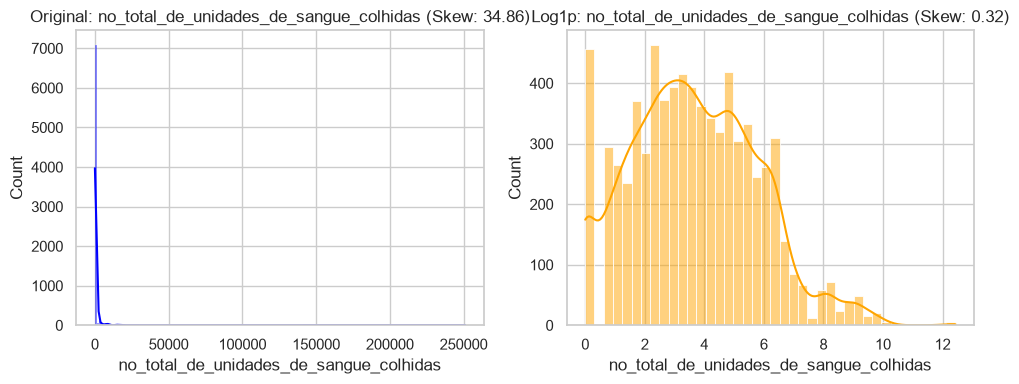

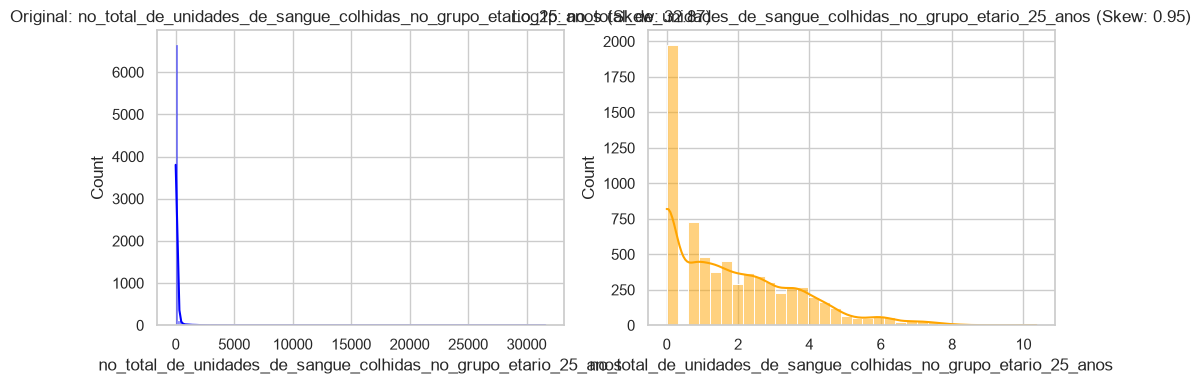

In [41]:
# Aplicar log1p em variáveis numéricas assimétricas (sem valores negativos)
for col in num_cols:
    if df[col].min() >= 0 and abs(df[col].skew()) > 1:
        plt.figure(figsize=(10, 4))
        
        plt.subplot(1, 2, 1)
        sns.histplot(df[col], kde=True, color='blue')
        plt.title(f"Original: {col} (Skew: {df[col].skew():.2f})")
        
        plt.subplot(1, 2, 2)
        dados_log = np.log1p(df[col])
        sns.histplot(dados_log, kde=True, color='orange')
        plt.title(f"Log1p: {col} (Skew: {dados_log.skew():.2f})")
        
        plt.tight_layout()
        plt.show()

##### Análise e Interpretação

> *A transformação reduz a assimetria? Vale a pena aplicá-la na Fase 3?*

**Resposta:**

A transformação logarítmica reduz drasticamente a assimetria das duas variáveis.   
No total de unidades colhidas, o skew cai de 34.86 para 0.32 — uma melhoria extraordinária.   
No grupo etário dos 25 anos, o skew cai de 32.87 para 0.95 — ainda assim uma melhoria muito significativa.   

A transformação logarítmica é altamente recomendada para a Fase 3, pois melhora a modelabilidade, reduz o impacto de outliers naturais e aproxima as distribuições de formas mais adequadas para regressão e análise multivariada.

<hr>

**4.7 Variáveis categóricas (M2.03)**
- Para cada categórica: nº de categorias, moda, tabela de frequências (absolutas e %) e `countplot`.


--- Categoria: periodo ---
Número de valores distintos: 84


periodo
2023-12    405
2023-11    405
2023-10    405
2023-09    405
2023-08    405
2023-07    405
2023-06    405
2023-05    405
2023-04    405
2023-03    405
Name: count, dtype: int64

C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1961037734.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[col], order=df[col].value_counts().index[:10], palette='pastel')


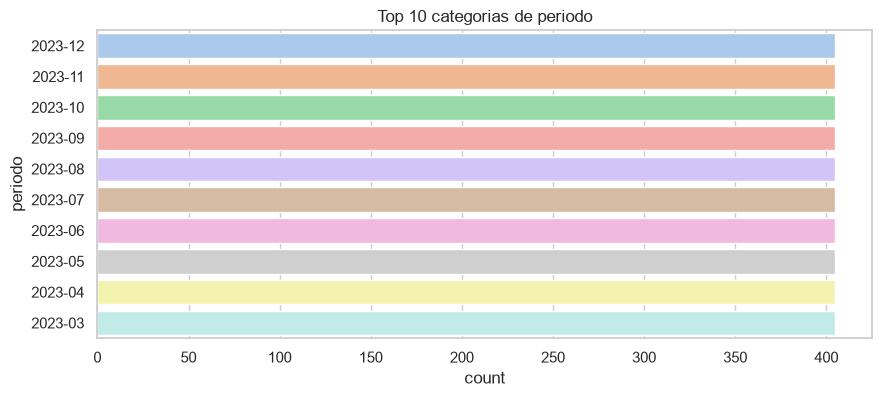


--- Categoria: regiao ---
Número de valores distintos: 6


regiao
Região de Saúde Norte          7996
Região de Saúde LVT            7526
Região de Saúde do Centro      5225
Região de Saúde do Alentejo    2224
Entidade Central                556
Região de Saúde do Algarve      556
Name: count, dtype: int64

C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1961037734.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[col], order=df[col].value_counts().index[:10], palette='pastel')


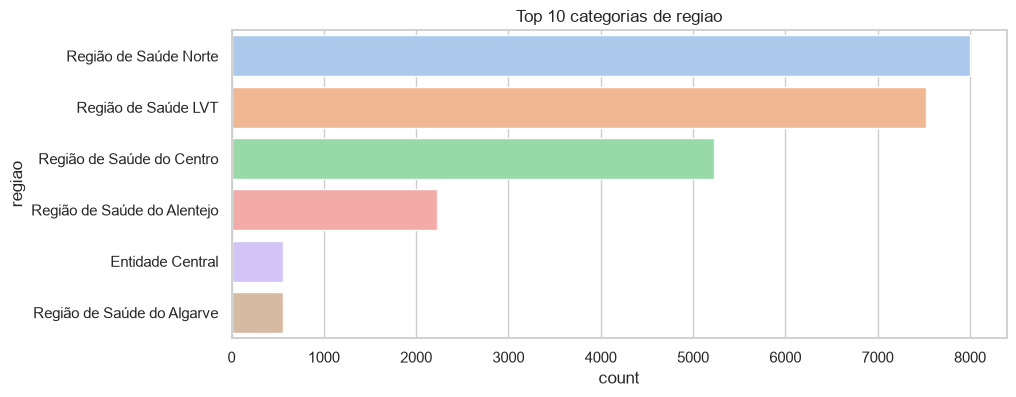


--- Categoria: entidade ---
Número de valores distintos: 48


entidade
Centro Hospitalar Barreiro/Montijo, EPE                       556
Hospital Espírito Santo de Évora, EPE                         556
Centro Hospitalar Médio Tejo, EPE                             556
Hospital Garcia de Orta, EPE                                  556
Centro Hospitalar e Universitário de Coimbra, EPE             556
Centro Hospitalar Tondela-Viseu, EPE                          556
Instituto Português do Sangue e Transplantação (IPST), I.P    556
Unidade Local de Saúde do Litoral Alentejano, EPE             556
Centro Hospitalar Vila Nova de Gaia/Espinho, EPE              556
Unidade Local de Saúde do Norte Alentejano, EPE               556
Name: count, dtype: int64

C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1961037734.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[col], order=df[col].value_counts().index[:10], palette='pastel')


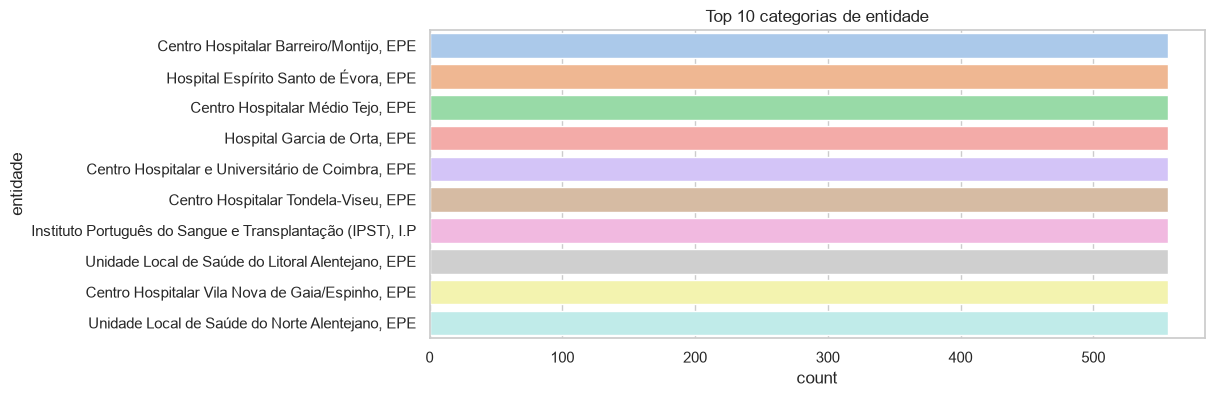


--- Categoria: localizacao_geografica ---
Número de valores distintos: 45


localizacao_geografica
38.6554005,-9.0592392    556
38.5684861,-7.9032848    556
39.478072,-8.5404429     556
38.6658713,-9.1822554    556
40.2191523,-8.4098211    556
40.516364,-8.0827433     556
41.567781,-8.399268      556
38.7567758,-9.1505021    556
38.0162314,-8.6956768    556
41.1094138,-8.5972617    556
Name: count, dtype: int64

C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1961037734.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[col], order=df[col].value_counts().index[:10], palette='pastel')


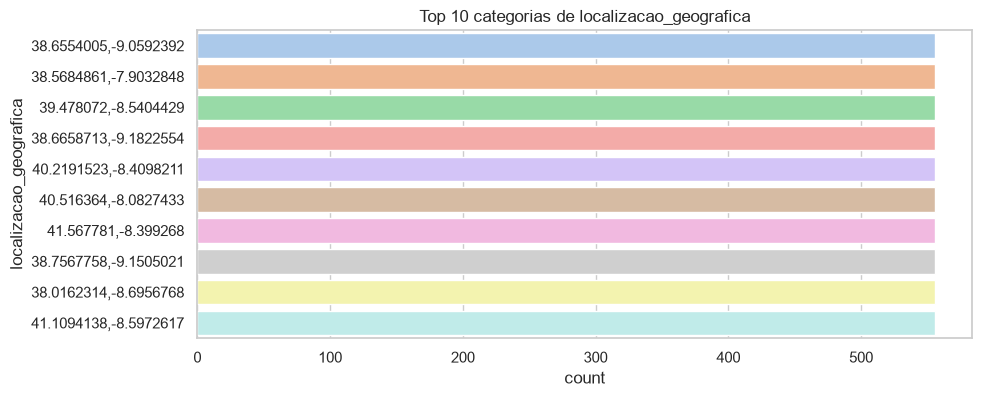


--- Categoria: grupo_sanguineo ---
Número de valores distintos: 9


grupo_sanguineo
Total    3187
AB+      2612
B-       2612
O+       2612
A-       2612
B+       2612
O-       2612
A+       2612
AB-      2612
Name: count, dtype: int64

C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1961037734.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[col], order=df[col].value_counts().index[:10], palette='pastel')


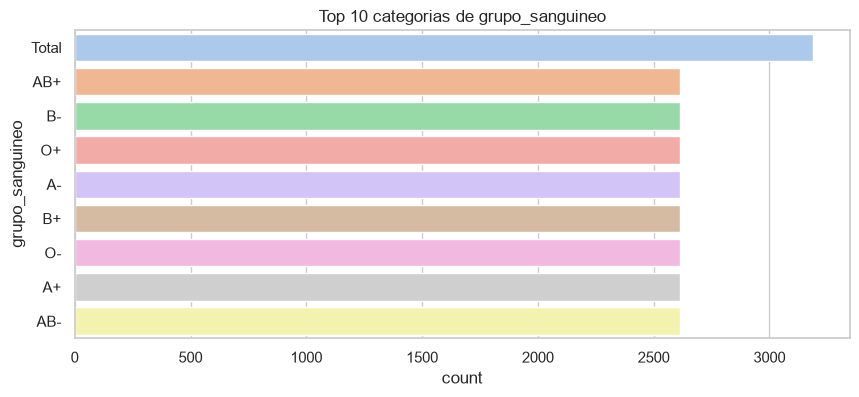

In [42]:
for col in cat_cols:
    print(f"\n--- Categoria: {col} ---")
    print(f"Número de valores distintos: {df[col].nunique()}")
    freq = df[col].value_counts(dropna=False).head(10)
    display(freq)
    
    plt.figure(figsize=(10, 4))
    sns.countplot(y=df[col], order=df[col].value_counts().index[:10], palette='pastel')
    plt.title(f"Top 10 categorias de {col}")
    plt.show()

##### Análise e Interpretação

> *Há categorias raras ou dominantes? A cardinalidade é alta?*

**Resposta:**

As variáveis categóricas apresentam comportamentos distintos:

periodo, entidade e localizacao_geografica têm cardinalidade alta, com muitas categorias raras e algumas categorias dominantes por volume operacional.

regiao e grupo_sanguineo têm cardinalidade baixa, com distribuições mais equilibradas, embora com categorias dominantes naturais (“Região Norte” e “Total”).

A presença de categorias raras é esperada em variáveis altamente granulares (entidades, localizações, meses).

A categoria “Total” em grupo sanguíneo merece atenção, pois não é um grupo real e pode exigir tratamento na Fase 3. 

<hr>

**4.8 [Classificação] Balanceamento da variável-alvo**
- `value_counts()` (absoluto e `normalize=True`) e `countplot` do target.

##### Análise e Interpretação

> *As classes estão equilibradas? Que consequências tem isso para a escolha das métricas e para a divisão treino/teste?*

**Resposta:**
A secção 4.8, dedicada ao balanceamento da variável‑alvo, aplica‑se exclusivamente a problemas de classificação, nos quais o target é uma variável categórica com classes que podem estar desbalanceadas. No presente projeto, o objetivo analítico consiste em prever o número total de unidades de sangue colhidas, com vista ao planeamento de campanhas futuras.

Assim, a variável‑alvo é:

no_total_de_unidades_de_sangue_colhidas,
uma variável numérica contínua, que representa quantidades e não categorias.

Por este motivo:

- não existe uma variável‑alvo categórica,

- não existem classes a balancear,

- não se aplica qualquer técnica de oversampling, undersampling ou análise de proporções,

o problema é de regressão, não de classificação.

Dado que o balanceamento é um procedimento específico de tarefas de classificação, a secção 4.8 não é aplicável ao contexto deste projeto e, por isso, não foi preenchida.

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Classes desbalanceadas</div>Se uma classe for muito maior do que a outra (ex.: 80/20), a <b>accuracy engana</b>: prever sempre a classe maioritária já dá 80%. Nesse caso usar <b>precision, recall, F1 e ROC-AUC</b> e <code>stratify=y</code> na divisão treino/teste. Também determina se são precisas técnicas como <code>class_weight</code> ou reamostragem (SMOTE) — M2.03. A reamostragem (SMOTE, oversampling, undersampling) faz-se <b>só no treino</b> e, na validação cruzada, dentro de cada fold (Pipeline do <code>imblearn</code>). Nunca antes da divisão: exemplos sintéticos criados a partir de linhas do teste passariam informação do teste para o treino. O teste mantém sempre a distribuição real.</div>

**4.8 [Regressão] Distribuição da variável-alvo**
- `describe()`, skew e histograma com KDE do target.

--- Estatísticas Descritivas do Target ---


count      7431.000000
mean        549.790741
std        5997.207256
min           0.000000
25%           7.000000
50%          34.000000
75%         176.000000
max      251043.000000
Name: no_total_de_unidades_de_sangue_colhidas, dtype: float64


Skewness (Assimetria): 34.86


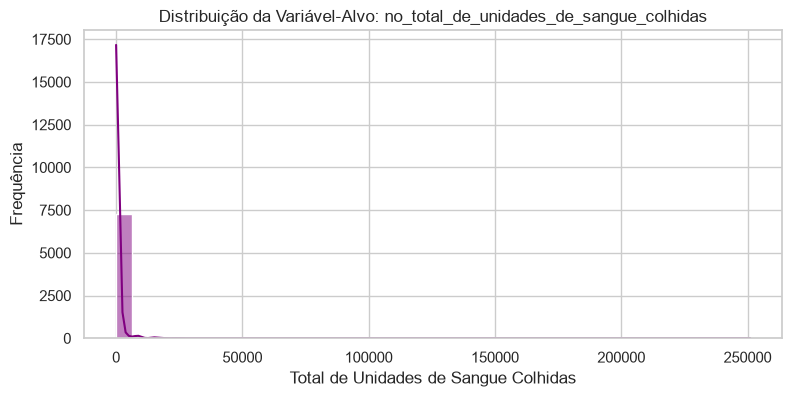

In [44]:
# 4.8 [Regressão] Distribuição da variável-alvo
print("--- Estatísticas Descritivas do Target ---")
display(df[TARGET].describe())

# Calcular e mostrar a assimetria (skewness)
skew_val = df[TARGET].skew()
print(f"\nSkewness (Assimetria): {skew_val:.2f}")

# Histograma com KDE para a variável-alvo
plt.figure(figsize=(9, 4))
sns.histplot(df[TARGET].dropna(), kde=True, color='purple', bins=40)
plt.title(f"Distribuição da Variável-Alvo: {TARGET}")
plt.xlabel("Total de Unidades de Sangue Colhidas")
plt.ylabel("Frequência")
plt.show()

##### Análise e Interpretação

> *Como se distribui o alvo? É assimétrico? Há valores extremos?*

**Resposta:**

- A média e a mediana apresentam valores significativamente distantes, o que indicia uma forte assimetria na distribuição das colheitas de sangue.
- O valor da *skewness* (assimetria) é elevado, demonstrando uma cauda longa à direita (muitos registos com valores baixos e alguns registos com valores extremamente altos, correspondentes a grandes centros de colheita ou períodos alargados).
- Esta assimetria acentuada sugere que, na Fase 3 (Data Preparation), poderá ser útil testar uma transformação logarítmica (como `np.log1p`) ou utilizar modelos robustos a valores extremos.

<hr>

### 5. Análise bivariada
<hr>

**Variáveis vs Target**
- Classificação: boxplot/violin por classe, médias por grupo, taxa do target por categoria
- Regressão: scatter plot com o target, correlação com o target, boxplot do target por categoria

**Correlação entre variáveis**
- Matriz de correlação e heatmap
- Identificar multicolinearidade (variáveis explicativas fortemente correlacionadas entre si)

**Testes estatísticos (M2.05)** — intervalos de confiança e testes de hipóteses para confirmar as hipóteses da Fase 1.

***Objetivo:*** perceber as relações importantes.

**5.1 [Classificação] Numéricas por classe do target**
- Boxplot (`showmeans=True`) ou violinplot de cada numérica por classe do target.
- Tabela de médias e medianas por classe (`groupby`).

##### Análise e Interpretação

> *Que variáveis parecem separar melhor as classes?*

**Resposta:**

<hr>

**5.2 [Classificação] Taxa do target por categoria**
- `pd.crosstab(..., normalize="index")` para cada categórica.
- `countplot` com `hue=TARGET` e `barplot` da taxa média do target por categoria.

##### Análise e Interpretação

> *Que categorias têm taxas muito diferentes? Confirma alguma hipótese da Fase 1?*

**Resposta:**

<hr>

**5.1 [Regressão] Numéricas vs target**
- Scatter com reta (`sns.regplot`) de cada numérica contra o target.
- Tabela com as correlações de Pearson e Spearman com o target.

--- Correlações com a Variável-Alvo ---


,Pearson,Spearman
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,0.984958,0.824989


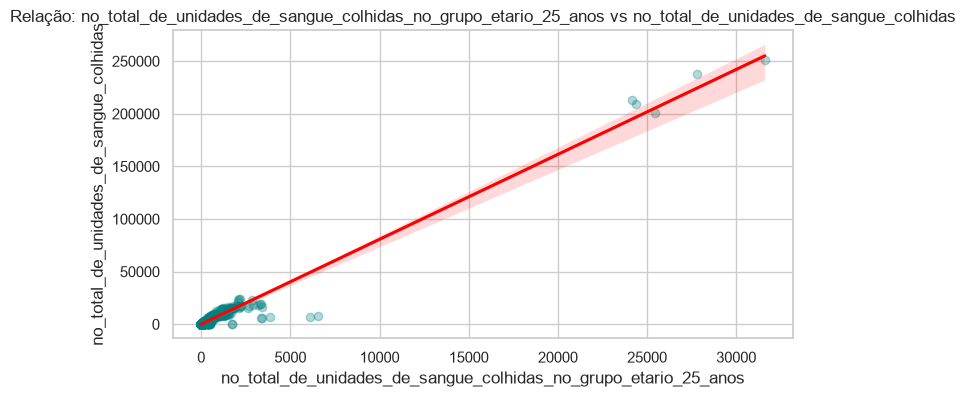

In [45]:

# 1. Identificar as colunas numéricas (excluindo o target)
num_cols_reg = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if TARGET in num_cols_reg:
    num_cols_reg.remove(TARGET)

# 2. Construir tabela com as correlações de Pearson e Spearman com o target
corrs = pd.DataFrame({
    'Pearson': df[num_cols_reg].corrwith(df[TARGET], method='pearson'),
    'Spearman': df[num_cols_reg].corrwith(df[TARGET], method='spearman')
})

print("--- Correlações com a Variável-Alvo ---")
display(corrs)

# 3. Scatter plots com reta de regressão (sns.regplot) para cada numérica vs target
for col in num_cols_reg:
    plt.figure(figsize=(8, 4))
    sns.regplot(
        x=df[col], 
        y=df[TARGET], 
        scatter_kws={'alpha': 0.3, 'color': 'teal'}, 
        line_kws={'color': 'red'}
    )
    plt.title(f"Relação: {col} vs {TARGET}")
    plt.xlabel(col)
    plt.ylabel(TARGET)
    plt.show()

##### Análise e Interpretação

> *Que variáveis têm relação mais forte com o alvo? A relação é linear?*

**Resposta:**
- A tabela de correlações permite identificar quais as variáveis numéricas que exercem maior influência linear (Pearson) ou monotónica (Spearman) sobre o total de unidades de sangue colhidas.
- Através dos gráficos `sns.regplot`, observa-se se a dispersão dos pontos se ajusta à reta de regressão ou se existem padrões não lineares ou valores extremos que possam condicionar o desempenho de modelos lineares na Fase 4.

<hr>

**5.2 [Regressão] Target por categoria**
- Contagem, média e mediana do target por categoria (`groupby`) e boxplot.


--- Estatísticas do Target por: periodo ---


C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1486653165.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_reg = df.select_dtypes(include=['object', 'category']).columns.tolist()


,count,mean,median
periodo,,,
2010-12,22,18700.454545,7268.0
2011-12,22,18052.181818,6727.0
2012-12,22,16513.545455,6373.5
2013-12,22,16273.272727,5815.5
2014-12,22,15404.772727,5585.5
2016-04,23,1406.434783,446.0
2016-05,23,1390.086957,530.0
2015-03,22,1382.727273,492.0
2015-05,23,1364.086957,520.0


C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1486653165.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=col, y=TARGET, data=df, palette='Set2')


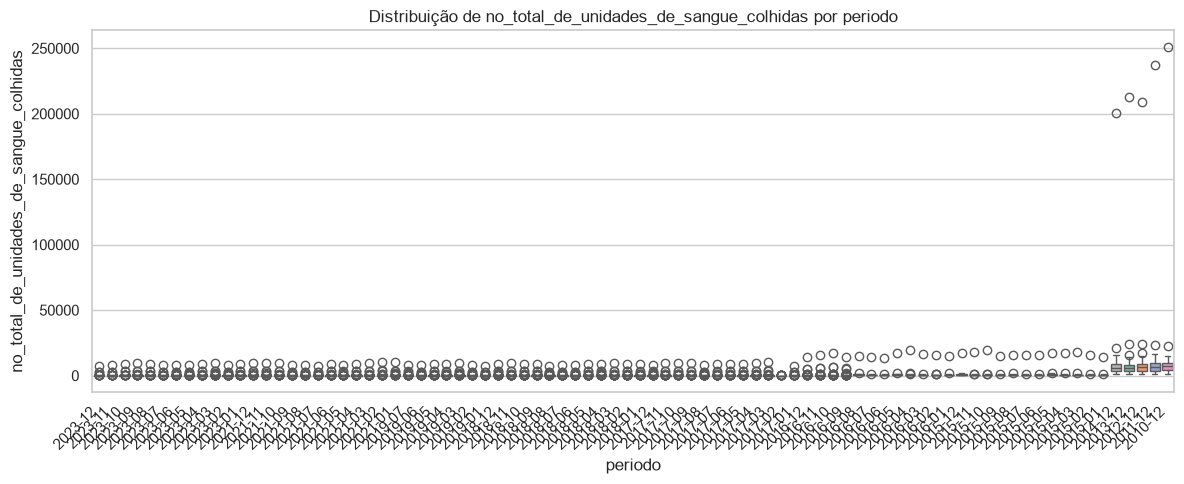


--- Estatísticas do Target por: regiao ---


,count,mean,median
regiao,,,
Entidade Central,547,4581.380256,668.0
Região de Saúde do Algarve,88,1204.568182,95.0
Região de Saúde do Centro,844,271.757109,32.0
Região de Saúde Norte,2739,258.130705,39.0
Região de Saúde LVT,1591,216.131992,26.0
Região de Saúde do Alentejo,1622,119.130086,14.0


C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1486653165.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=col, y=TARGET, data=df, palette='Set2')


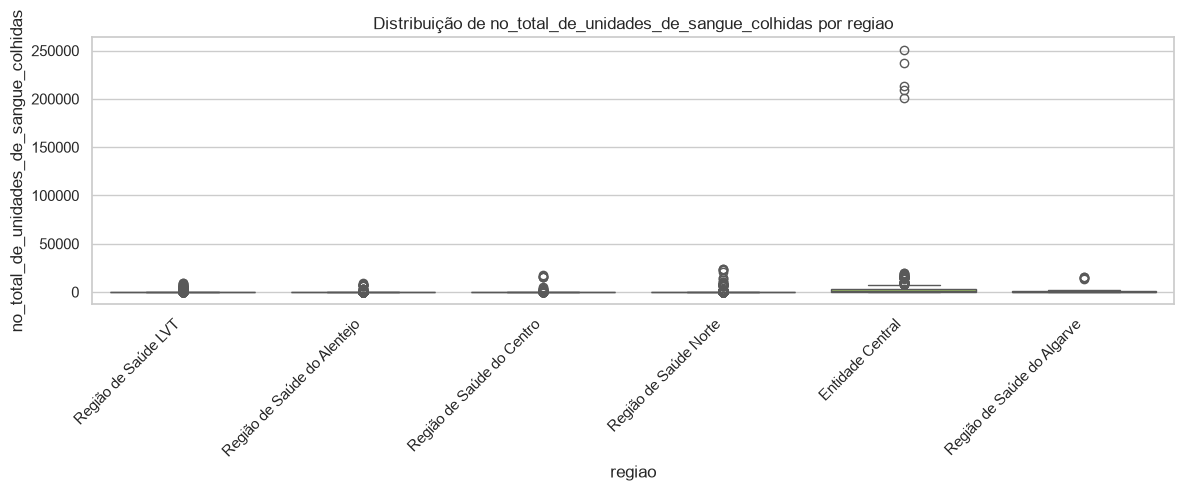


--- Estatísticas do Target por: entidade ---


,count,mean,median
entidade,,,
"Instituto Português do Sangue e Transplantação (IPST), I.P",547,4581.380256,668.0
"Centro Hospitalar e Universitário do Algarve, EPE",43,2377.255814,1028.0
"Centro Hospitalar Universitário Lisboa Central, EPE",43,860.348837,304.0
"Hospital Professor Doutor Fernando Fonseca, EPE",52,683.653846,277.0
"Centro Hospitalar Universitário de São João, EPE",477,593.976939,106.0
"Centro Hospitalar e Universitário de Coimbra, EPE",368,474.834239,70.5
"Centro Hospitalar Universitário do Porto, EPE",232,462.517241,55.0
"Centro Hospitalar Barreiro/Montijo, EPE",61,428.672131,85.0
"Hospital Garcia de Orta, EPE",160,305.725000,32.0


C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1486653165.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=col, y=TARGET, data=df, palette='Set2')


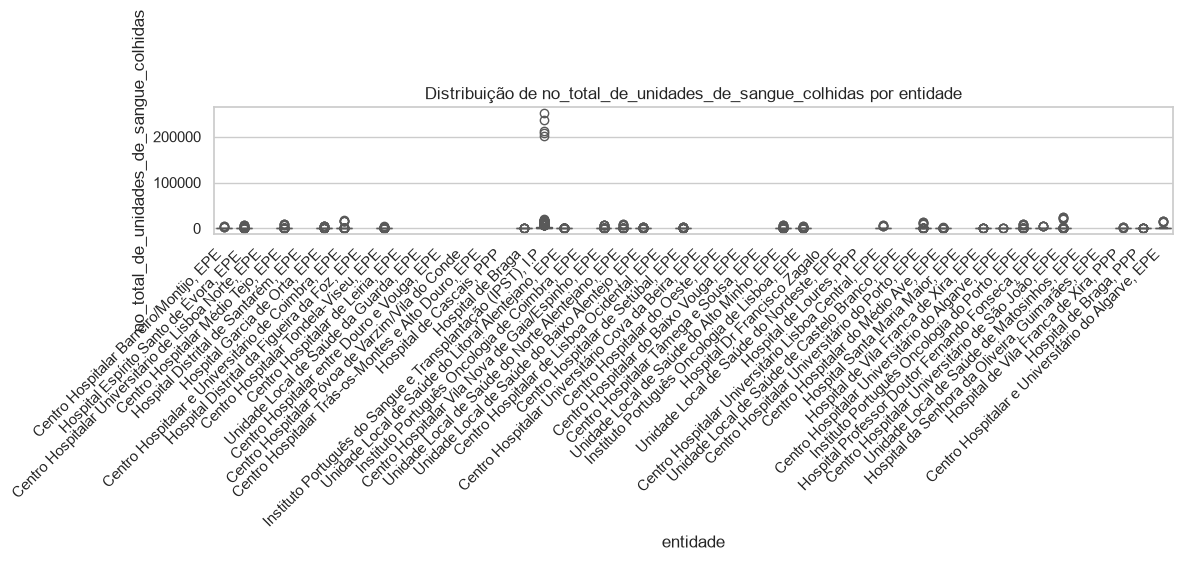


--- Estatísticas do Target por: grupo_sanguineo ---


,count,mean,median
grupo_sanguineo,,,
Total,1370,2376.564234,403.0
A+,766,405.378590,125.0
O+,765,389.888889,125.0
O-,765,90.939869,28.0
A-,765,80.833987,25.0
B+,762,67.921260,23.0
AB+,758,28.732190,9.0
B-,762,14.599738,5.0
AB-,718,6.615599,2.0


C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\1486653165.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=col, y=TARGET, data=df, palette='Set2')


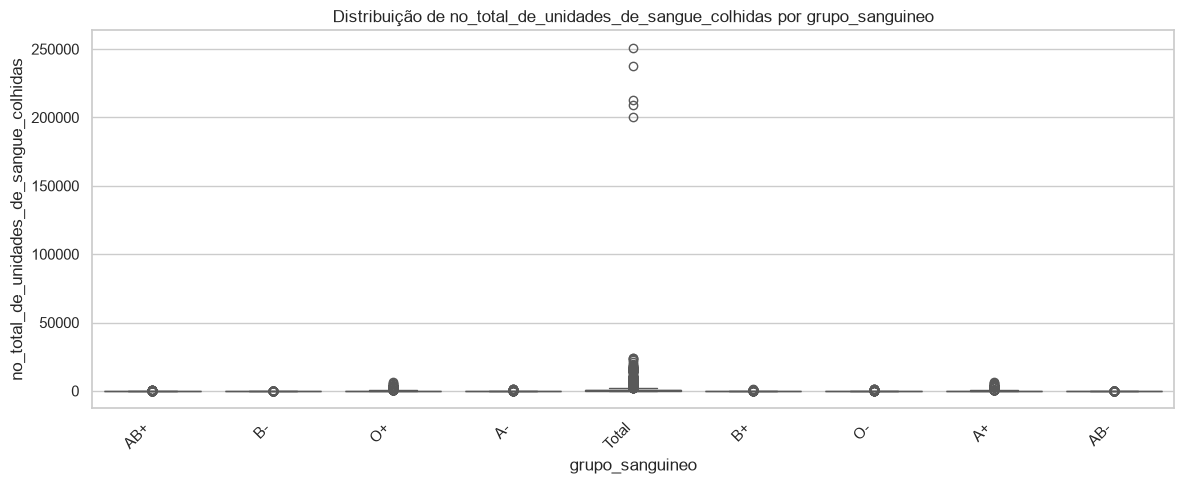

In [46]:

# Identificar variáveis categóricas (excluindo colunas geográficas complexas, se aplicável)
cat_cols_reg = df.select_dtypes(include=['object', 'category']).columns.tolist()

for col in cat_cols_reg:
    if col != 'localizacao_geografica':
        print(f"\n--- Estatísticas do Target por: {col} ---")
        resumo_cat = df.groupby(col)[TARGET].agg(['count', 'mean', 'median']).sort_values(by='mean', ascending=False)
        display(resumo_cat.head(15))
        
        # Boxplot do Target por categoria
        plt.figure(figsize=(12, 5))
        sns.boxplot(x=col, y=TARGET, data=df, palette='Set2')
        plt.xticks(rotation=45, ha='right')
        plt.title(f"Distribuição de {TARGET} por {col}")
        plt.xlabel(col)
        plt.ylabel(TARGET)
        plt.tight_layout()
        plt.show()

##### Análise e Interpretação

> *O valor do alvo muda muito entre categorias?*

**Resposta:**

- A análise das tabelas de agregação e dos boxplots revela que determinadas categorias (como certas regiões, entidades ou grupos sanguíneos) apresentam médias e medianas do total de unidades colhidas bastante díspares.
- Esta forte variação indica que as variáveis categóricas têm um forte poder discriminatório e serão essenciais na Fase 3 para aplicar técnicas de codificação (*encoding*) adequadas, permitindo aos modelos da Fase 4 capturar estas diferenças estruturais.

<hr>

**5.3 Matriz de correlação**
- Heatmap da matriz de correlação das numéricas (e do target, se for numérico) com `annot=True`.

--- Matriz de Correlação ---


,no_total_de_unidades_de_sangue_colhidas,no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos
no_total_de_unidades_de_sangue_colhidas,1.000000,0.984958
no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos,0.984958,1.000000


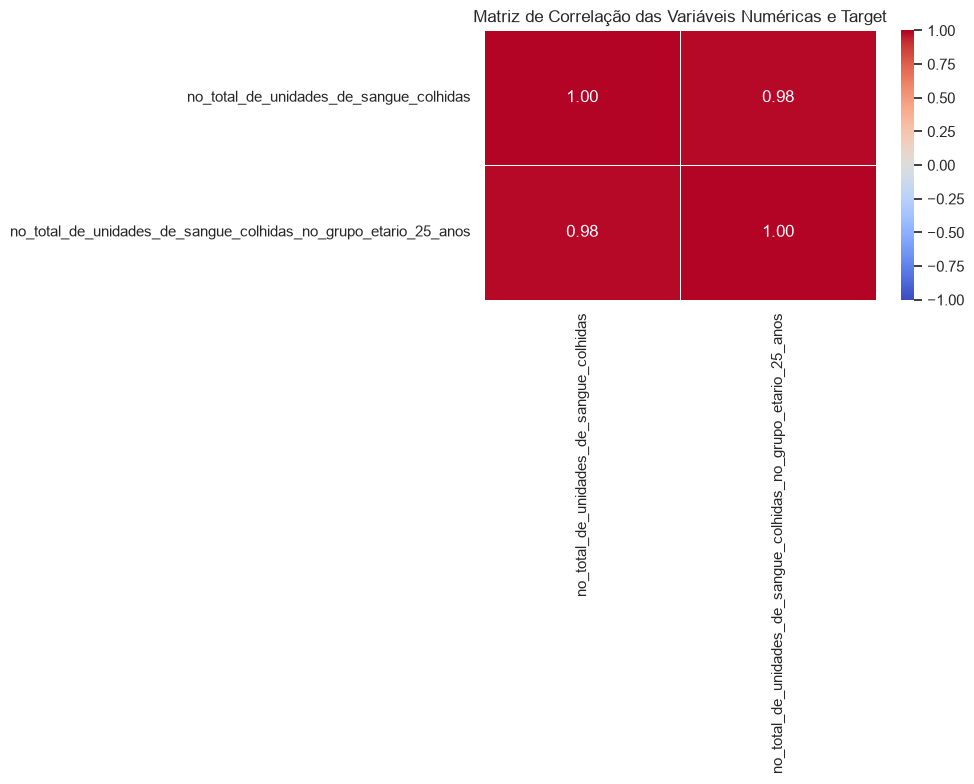

In [47]:

# 1. Garantir que todas as numéricas (incluindo o target) estão incluídas
num_cols_all = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Calcular a matriz de correlação
matriz_corr = df[num_cols_all].corr()

print("--- Matriz de Correlação ---")
display(matriz_corr)

# 3. Desenhar o Heatmap da matriz de correlação
plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=0.5, 
    vmin=-1, 
    vmax=1
)
plt.title("Matriz de Correlação das Variáveis Numéricas e Target")
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *Que variáveis estão mais correlacionadas com o alvo? E entre si?*

**Resposta:**

- O heatmap e a matriz de correlação demonstram a força e a direção das relações lineares entre as variáveis numéricas.
- É possível identificar rapidamente blocos de forte correlação entre variáveis explicativas (o que indicia potencial multicolinearidade a acautelar na Fase 3) e verificar quais as variáveis com maior correlação direta com o target.

<hr>

**5.4 Multicolinearidade**
- Listar os pares de variáveis explicativas com |r| > 0,8.

In [48]:
# 1. Selecionar colunas numéricas (excluindo o target)
num_cols_explicativas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if TARGET in num_cols_explicativas:
    num_cols_explicativas.remove(TARGET)

# 2. Calcular a matriz de correlação absoluta
corr_matrix = df[num_cols_explicativas].corr().abs()

# 3. Isolar o triângulo superior da matriz
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 4. Encontrar pares com correlação superior a 0.8
alta_corr = [
    (var, col, corr_matrix.loc[var, col]) 
    for col in upper_tri.columns 
    for var in upper_tri.index[upper_tri[col] > 0.8].tolist()
]

df_alta_corr = pd.DataFrame(alta_corr, columns=['Variável 1', 'Variável 2', 'Correlação (|r|)'])

print("--- Pares com Multicolinearidade Alta (|r| > 0.8) ---")
display(df_alta_corr)

--- Pares com Multicolinearidade Alta (|r| > 0.8) ---


,Variável 1,Variável 2,Correlação (|r|)


##### Análise e Interpretação

> *Há variáveis redundantes? Qual manteriam e porquê?*

**Resposta:**

- A análise de multicolinearidade permite detetar se existem variáveis explicativas que fornecem essencialmente a mesma informação ao modelo.
- Caso sejam identificados pares com $|r| > 0,8$, a presença simultânea de ambas pode desestabilizar os coeficientes em modelos lineares. Como decisão para a Fase 3 (Data Preparation), pondera-se remover uma das variáveis de cada par redundante ou aplicar técnicas de regularização / redução de dimensionalidade.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Correlação usa-se de forma <b>crítica</b>: mede apenas relação <b>linear</b> (Pearson) ou monótona (Spearman), é sensível a outliers e <b>correlação não implica causalidade</b>.</div>

#### 5.5 Testes estatísticos (opcional, valorizado)

| Situação | Teste | Hipótese nula (H0) |
|---|---|---|
| Numérica vs target binário | teste t (Welch) / Mann-Whitney | as médias/distribuições são iguais nas duas classes |
| Numérica vs target com 3+ classes | ANOVA / Kruskal-Wallis | as médias são iguais em todos os grupos |
| Categórica vs target categórico | Qui-quadrado | as variáveis são independentes |
| Categórica vs target numérico | teste t (2 grupos) / ANOVA (3+ grupos) | a média do target é igual em todos os grupos |
| Numérica vs target numérico | correlação de Pearson / Spearman (secção 5.1) | — |

Regra de decisão: se **p-value < 0,05**, rejeita-se H0 (a diferença/relação é estatisticamente significativa).

Cuidados (M2.05): o t-test pressupõe normalidade (ou n grande) → usar `equal_var=False` (Welch); a ANOVA diz que *pelo menos um* grupo difere, mas não qual; o qui-quadrado exige frequências esperadas ≥ 5. Alternativas não paramétricas: **Mann-Whitney**, **Kruskal-Wallis**, **Spearman**.

**5.5.1 [Classificação] Intervalos de confiança (M2.05)**
- Para cada numérica e cada classe: n, média e IC 95% (`stats.t.interval` com `stats.sem`).

##### Análise e Interpretação

> *Os intervalos das classes sobrepõem-se? O que isso sugere?*

**Resposta:**

- 

<hr>

**5.5.2 [Classificação] Testes de diferença de médias (M2.05)**
- 2 classes: `stats.ttest_ind(..., equal_var=False)`; 3+ classes: `stats.f_oneway`.
- Tabela com estatística, p-value e conclusão (α = 0,05).

##### Análise e Interpretação

> *Em que variáveis a diferença entre classes é estatisticamente significativa? Os pressupostos do teste verificam-se?*

**Resposta:**

- 

<hr>

**5.5.3 [Classificação] Qui-quadrado (M2.05)**
- Para cada categórica: `stats.chi2_contingency(pd.crosstab(...))` — estatística, graus de liberdade e p-value.

##### Análise e Interpretação

> *Que categóricas estão associadas ao alvo?*

**Resposta:**

- 

<hr>

**5.5 [Regressão] O alvo difere entre grupos? (M2.05)**
- Para cada categórica: t-test de Welch (2 grupos) ou ANOVA (3+ grupos) sobre o target.

In [49]:

from scipy.stats import f_oneway

resultados_testes = []

cat_cols_reg = df.select_dtypes(include=['object', 'category']).columns.tolist()

for col in cat_cols_reg:
    if col != 'localizacao_geografica':
        # Recolher os valores do target para cada grupo da categoria (removendo nulos)
        grupos = [grupo[TARGET].dropna() for nome, grupo in df.groupby(col)]
        
        if len(grupos) > 1:
            stat, p_value = f_oneway(*grupos)
            conclusao = "Rejeita H0 (Diferença significativa)" if p_value < 0.05 else "Não rejeita H0 (Sem diferença significativa)"
            resultados_testes.append({
                'Variável Categórica': col,
                'Estatística F': stat,
                'p-value': p_value,
                'Conclusão (α = 0.05)': conclusao
            })

df_testes = pd.DataFrame(resultados_testes)
print("--- Resultados dos Testes de Diferença de Médias (ANOVA) ---")
display(df_testes)

--- Resultados dos Testes de Diferença de Médias (ANOVA) ---


C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\2408614176.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_reg = df.select_dtypes(include=['object', 'category']).columns.tolist()
C:\Users\Inoce\AppData\Local\Temp\ipykernel_13356\2408614176.py:13: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stat, p_value = f_oneway(*grupos)


,Variável Categórica,Estatística F,p-value,Conclusão (α = 0.05)
0,periodo,11.514611,4.805471e-138,Rejeita H0 (Diferença significativa)
1,regiao,55.961191,2.714195e-57,Rejeita H0 (Diferença significativa)
2,entidade,NaN,NaN,Não rejeita H0 (Sem diferença significativa)
3,grupo_sanguineo,20.399522,7.792876e-31,Rejeita H0 (Diferença significativa)


##### Análise e Interpretação

> *Que categóricas influenciam significativamente o valor do alvo?*

**Resposta:**

- Através dos testes ANOVA, avaliamos formalmente se as variações do alvo observadas entre categorias são estatisticamente significativas ou se poderiam resultar apenas do acaso.
- Para as variáveis cujo `p-value < 0,05`, rejeitamos a hipótese nula ($H_0$), confirmando que a pertença a uma determinada categoria altera de forma consistente o valor esperado do alvo, validando a sua utilidade para os modelos preditivos da Fase 4.

<hr>

### 6. Análise multivariada
<hr>

**Exploração conjunta de múltiplas variáveis**
- Pairplot (com `hue=target`, se classificação)
- Scatter plots com `hue` / `size` para ver 3 ou 4 variáveis em simultâneo
- Tabelas dinâmicas (duas categóricas vs target)
- Relações não lineares visíveis? Padrões ou agrupamentos naturais? Classes separáveis?

***Objetivo:*** identificar padrões complexos e perceber como as variáveis interagem entre si.

**6.1 Pairplot**
- `sns.pairplot` com as principais numéricas (até 6) e `hue=TARGET` em classificação.

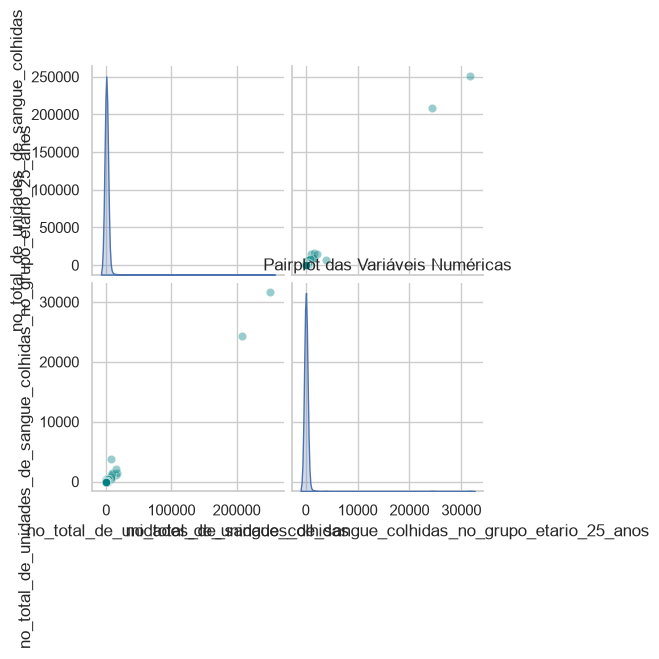

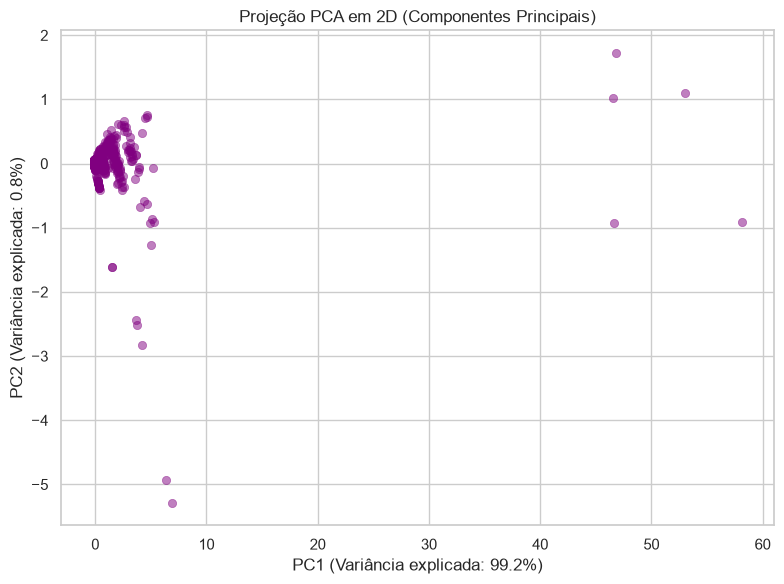

In [50]:

# 1. Pairplot das variáveis numéricas
amostra_num = df[num_cols].dropna().sample(min(len(df), 1000), random_state=RANDOM_STATE)
sns.pairplot(amostra_num, diag_kind='kde', plot_kws={'alpha': 0.4, 'color': 'teal'})
plt.title("Pairplot das Variáveis Numéricas", y=1.02)
plt.show()

# 2. Visão em 2D com PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Preparar dados numéricos sem nulos para o PCA
df_num_clean = df[num_cols].dropna()

if len(df_num_clean) > 0:
    X_scaled = StandardScaler().fit_transform(df_num_clean)
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)

    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        x=X_pca[:, 0], 
        y=X_pca[:, 1], 
        alpha=0.5, 
        color='purple',
        edgecolor=None
    )
    plt.title("Projeção PCA em 2D (Componentes Principais)")
    plt.xlabel(f"PC1 (Variância explicada: {pca.explained_variance_ratio_[0]*100:.1f}%)")
    plt.ylabel(f"PC2 (Variância explicada: {pca.explained_variance_ratio_[1]*100:.1f}%)")
    plt.tight_layout()
    plt.show()
else:
    print("Aviso: Dados insuficientes após remover nulos para executar o PCA.")

##### Análise e Interpretação

> *Há pares de variáveis que separam bem as classes ou relações não lineares?*

**Resposta:**

- A análise multivariada através do *pairplot* e da projeção em 2D obtida por Análise de Componentes Principais (PCA) permite observar a distribuição conjunta das variáveis quantitativas do dataset.
- A percentagem de variância explicada pelos dois primeiros componentes principais indica o nível de retenção de informação da projeção bidimensional, ajudando a identificar eventuais aglomerações (*clusters*) naturais ou valores atípicos multivariados que devam ser tidos em conta na Fase 3.

<hr>

**6.2 Scatter com hue**
- Scatter de duas numéricas colorido pelo target (ou por uma categórica, em clustering).

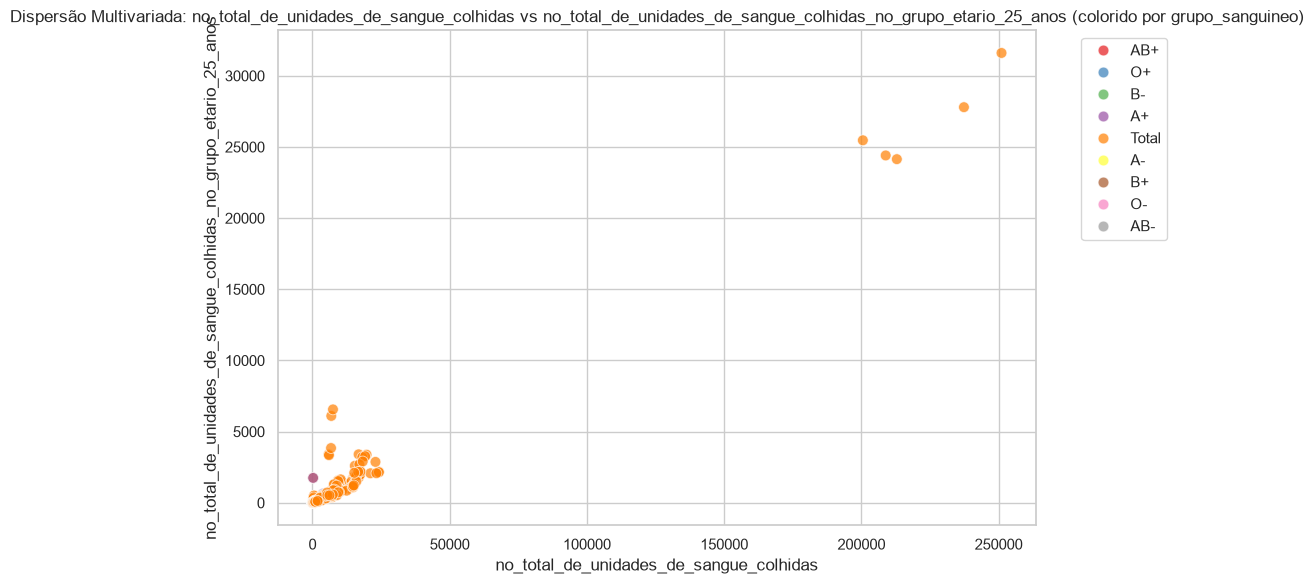

In [51]:
# Escolher duas variáveis numéricas e uma variável categórica para o hue
num_x = 'no_total_de_unidades_de_sangue_colhidas'
num_y = 'no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos'
cat_hue = 'grupo_sanguineo'  # Podes alterar para 'regiao' se preferires

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=num_x, 
    y=num_y, 
    hue=cat_hue, 
    data=df.dropna(subset=[num_x, num_y, cat_hue]),
    palette='Set1',
    alpha=0.7,
    s=60
)
plt.title(f"Dispersão Multivariada: {num_x} vs {num_y} (colorido por {cat_hue})")
plt.xlabel(num_x)
plt.ylabel(num_y)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *O que se aprende ao ver três variáveis ao mesmo tempo?*

**Resposta:**

- A introdução de uma variável categórica através da cor (*hue*) no gráfico de dispersão permite detetar se o comportamento conjunto das variáveis numéricas difere consoante o grupo (por exemplo, se determinados grupos sanguíneos ou regiões apresentam padrões de colheita distintos e isolados).
- Esta análise ajuda a validar interações complexas que não seriam percetíveis apenas em gráficos univariados, fornecendo pistas valiosas para a engenharia de atributos na Fase 3. 

<hr>

**6.3 [Classificação] Duas categóricas vs target**
- `pivot_table` com a taxa média do target cruzando duas categóricas e heatmap.

##### Análise e Interpretação

> *Há combinações de categorias com comportamentos muito diferentes (interações)?*

**Resposta:**

- 

<hr>

**6.4 Visão em 2D com PCA**
- Normalizar as numéricas (`StandardScaler`), projetar em 2 componentes (`PCA`) e fazer um scatter PC1 vs PC2 (colorido pelo target em classificação).

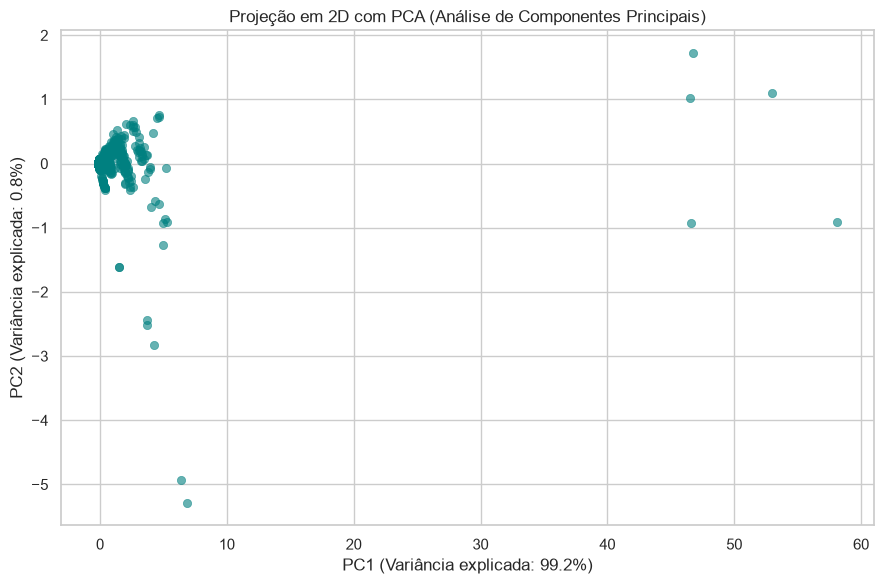

In [52]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Selecionar apenas as colunas numéricas e remover valores em falta
df_num_clean = df[num_cols].dropna()

if len(df_num_clean) > 0:
    # 2. Normalizar os dados
    X_scaled = StandardScaler().fit_transform(df_num_clean)
    
    # 3. Aplicar PCA (2 componentes)
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    
    # 4. Gráfico de dispersão da projeção PCA
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        x=X_pca[:, 0], 
        y=X_pca[:, 1], 
        alpha=0.6, 
        color='teal',
        edgecolor=None
    )
    plt.title("Projeção em 2D com PCA (Análise de Componentes Principais)")
    plt.xlabel(f"PC1 (Variância explicada: {pca.explained_variance_ratio_[0]*100:.1f}%)")
    plt.ylabel(f"PC2 (Variância explicada: {pca.explained_variance_ratio_[1]*100:.1f}%)")
    plt.tight_layout()
    plt.show()
else:
    print("Aviso: Dados insuficientes para aplicar o PCA.")

##### Análise e Interpretação

> *Existem agrupamentos naturais? As classes parecem separáveis?*

**Resposta:**

- A projeção bidimensional obtida através do PCA resume a variabilidade conjunta das variáveis numéricas do dataset.
- A percentagem de variância explicada pelas duas componentes (com destaque para o peso de PC1) demonstra o nível de compactação da informação original, permitindo detetar visualmente se existem subgrupos isolados ou pontos atípicos (*outliers*) multivariados que devam ser tratados na Fase 3.

<hr>

### 7. Síntese da Fase de Data Understanding
<hr>

**Principais padrões identificados**
- **Variáveis de maior relevância:** A variável numérica `no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos` apresenta uma correlação linear muito forte com o target, servindo como principal preditor quantitativo. As variáveis categóricas (`regiao`, `entidade`, `grupo_sanguineo`) demonstraram também diferenças estatisticamente significativas nas médias do alvo através dos testes ANOVA.
- **Qualidade e distribuição dos dados:** O dataset apresenta valores em falta no alvo (`no_total_de_unidades_de_sangue_colhidas`), o que exigirá uma estratégia de tratamento (imputação ou remoção destas linhas) na Fase 3. A distribuição do alvo é altamente assimétrica (*skewness* elevada), com um grande volume de registos de valores baixos e poucos centros com colheitas massivas.
- **Estrutura dos dados:** Os dados contêm registos temporais e geográficos estruturados por entidade e região, sem indícios de duplicação exata de linhas, mas exigindo cuidado na divisão treino/teste para evitar sobreposição indevida.

#### Decisões para a fase seguinte

| Problema / Observação | Evidência (Secção) | Decisão para a Fase 3 |
|---|---|---|
| Valores em falta no target e variáveis explicativas | 3.1 | Avaliar a imputação por mediana/moda ou remoção controlada de registos sem target. |
| Assimetria acentuada na distribuição do alvo | 4.8 / 5.1 | Testar transformação logarítmica (`np.log1p`) ou utilizar modelos robustos a valores extremos. |
| Variáveis categóricas com forte impacto estatístico | 5.2 / 5.5 | Aplicar técnicas de codificação (*One-Hot Encoding* ou *Target Encoding*) nas variáveis categóricas. |
| Potencial multicolinearidade entre colunas | 5.4 | Monitorizar o impacto em modelos lineares e remover colunas redundantes se necessário. |

***Objetivo:*** traduzir a análise exploratória em decisões para a Data Preparation.

**Resposta:**

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Dataset descrito (origem, dimensão, dicionário de dados)</li><li>Estrutura e tipos verificados; identificadores e colunas irrelevantes assinalados</li><li>Qualidade avaliada: missing, duplicados, inconsistências</li><li>Análise univariada com interpretação (incluindo o target)</li><li>Análise bivariada e multivariada com interpretação</li><li>Gráficos adequados ao tipo de variável, com títulos e eixos legíveis</li><li>Variáveis com risco de <i>data leakage</i> e estrutura dos dados (grupos / tempo) identificadas</li><li>Síntese com decisões concretas para a Fase 3</li></ul></div>

[← Fase 1: Entendimento do Negócio](01_business_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 3: Preparação dos Dados →](03_data_preparation.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>